# 26. CN7 R1 안에서 정상 vs 불량 — 무엇이 다른가

Run 간 차이(R1 전체가 금형온도 25℃ 등)를 뺀 **R1 내부 비교**
- **① R1 정상 전체**와 비교 / **② 시간 맞춘 정상**(각 불량 샷 앞뒤 ±10샷 안의 정상)과 비교 → ②가 가장 엄격
- 변수: 원값 21개 + 최종 모델 파생변수 17개 + 최종 모델 점수
- Cliff's δ: |δ| ≥ 0.33 중간, ≥ 0.47 큼 / q(BH): 변수 39개를 동시에 검정한 보정 p
- 불량 샷 하나하나의 점수·이상 원인 후보·상위 기여 변수도 함께 (24번 방식)

※ 09번(R1 비교)의 확장판: 최종 모델 파생변수·점수·기여도를 추가하고 다중검정 보정을 넣음

In [1]:
import os
import pandas as pd
from r1_inside import load_run, compare, positions, defect_cases, plot_timeline
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 70)
OUT = './outputs/r1_inside'
os.makedirs(OUT, exist_ok=True)

d, model, RUN = load_run('cn7')
print(RUN, f'{len(d)}샷'); display(d.groupby('group').size().rename('샷 수').to_frame())

cn7_R1 188샷


,샷 수
group,
가스,11
미성형계열,3
정상,174


## 1. 불량 위치 (Run 내 순번) — 몰려 있나

In [2]:
display(positions(d))

,불량,샷 수,위치(seq),범위(첫~끝 간격),Run 길이,군집 p(이만큼 좁게 모일 확률)
0,가스,11,"[25, 41, 49, 51, 52, 53, 54, 55, 56, 57, 58]",33,188,0.0000
1,미성형계열,3,"[59, 60, 61]",2,188,0.0002


## 2. 가스 vs 정상 — 차이가 큰 변수 (|δ| 순)

In [3]:
G = compare(d, '가스'); G.to_csv(f'{OUT}/gas_vs_normal.csv', index=False, encoding='utf-8-sig')
cols = ['비교', '이름', 'n불량', 'n정상', '불량 중앙값', '정상 중앙값', '차이', "Cliff's δ", '효과', 'p', 'q(BH)']
for b in G['비교'].unique():
    print(b); display(G[G['비교'] == b][cols].head(15).round(3))

① R1 정상 전체


,비교,이름,n불량,n정상,불량 중앙값,정상 중앙값,차이,Cliff's δ,효과,p,q(BH)
8,① R1 정상 전체,Clamp_Close_Time,11,174,7.130,7.120,0.010,0.653,큼,0.000,0.001
72,① R1 정상 전체,호퍼온도 추세,11,172,0.020,0.001,0.019,0.542,큼,0.003,0.050
64,① R1 정상 전체,호퍼온도,11,169,3.000,0.000,3.000,0.519,큼,0.004,0.050
62,① R1 정상 전체,금형온도,11,169,-1.000,0.000,-1.000,-0.423,중간,0.015,0.143
36,① R1 정상 전체,Hopper_Temperature,11,174,67.300,67.100,0.200,0.363,중간,0.043,0.290
68,① R1 정상 전체,호퍼온도 상승량,11,174,0.320,0.120,0.200,0.359,중간,0.045,0.290
34,① R1 정상 전체,Barrel_Temperature_6,11,174,230.200,230.000,0.200,0.346,중간,0.052,0.290
22,① R1 정상 전체,Average_Back_Pressure,11,174,59.200,59.100,0.100,0.308,작음,0.081,0.322
38,① R1 정상 전체,Mold_Temperature_3,11,174,25.100,25.000,0.100,0.301,작음,0.077,0.322
66,① R1 정상 전체,금형온도 상승량,11,174,0.180,0.080,0.100,0.297,작음,0.083,0.322


② 시간 맞춘 정상(±10샷)


,비교,이름,n불량,n정상,불량 중앙값,정상 중앙값,차이,Cliff's δ,효과,p,q(BH)
73,② 시간 맞춘 정상(±10샷),호퍼온도 추세,11,40,0.020,-0.002,0.022,0.755,큼,0.000,0.006
65,② 시간 맞춘 정상(±10샷),호퍼온도,11,40,3.000,0.000,3.000,0.620,큼,0.002,0.021
37,② 시간 맞춘 정상(±10샷),Hopper_Temperature,11,40,67.300,67.000,0.300,0.600,큼,0.002,0.021
69,② 시간 맞춘 정상(±10샷),호퍼온도 상승량,11,40,0.320,0.020,0.300,0.600,큼,0.002,0.021
63,② 시간 맞춘 정상(±10샷),금형온도,11,40,-1.000,0.000,-1.000,-0.534,큼,0.006,0.046
5,② 시간 맞춘 정상(±10샷),Plasticizing_Time,11,40,16.920,16.910,0.010,0.409,중간,0.039,0.254
45,② 시간 맞춘 정상(±10샷),충전시간,11,40,0.000,-0.506,0.506,0.370,중간,0.061,0.337
35,② 시간 맞춘 정상(±10샷),Barrel_Temperature_6,11,40,230.200,230.050,0.150,0.309,작음,0.117,0.568
59,② 시간 맞춘 정상(±10샷),충전 이상지표,11,40,0.000,-0.843,0.843,0.266,작음,0.184,0.649
71,② 시간 맞춘 정상(±10샷),금형온도 추세,11,40,0.004,0.006,-0.002,-0.264,작음,0.188,0.649


## 3. 미성형계열 vs 정상 (샷 수가 적어 참고용)

In [4]:
M = compare(d, '미성형계열'); M.to_csv(f'{OUT}/short_vs_normal.csv', index=False, encoding='utf-8-sig')
for b in M['비교'].unique():
    print(b); display(M[M['비교'] == b][cols].head(10).round(3))

① R1 정상 전체


,비교,이름,n불량,n정상,불량 중앙값,정상 중앙값,차이,Cliff's δ,효과,p,q(BH)
0,① R1 정상 전체,Injection_Time,3,174,9.450,9.580,-0.130,-1.0,큼,0.002,0.01
2,① R1 정상 전체,Filling_Time,3,174,4.330,4.460,-0.130,-1.0,큼,0.002,0.01
10,① R1 정상 전체,Cushion_Position,3,174,653.400,653.410,-0.010,-1.0,큼,0.000,0.00
14,① R1 정상 전체,Max_Injection_Speed,3,174,60.800,55.500,5.300,1.0,큼,0.003,0.01
18,① R1 정상 전체,Max_Injection_Pressure,3,174,141.400,141.700,-0.300,-1.0,큼,0.001,0.01
42,① R1 정상 전체,사출속도,3,169,35.749,0.000,35.749,1.0,큼,0.003,0.01
44,① R1 정상 전체,충전시간,3,169,-8.769,0.000,-8.769,-1.0,큼,0.003,0.01
52,① R1 정상 전체,쿠션위치,3,169,-0.995,0.000,-0.995,-1.0,큼,0.000,0.00
58,① R1 정상 전체,충전 이상지표,3,169,-44.517,0.000,-44.517,-1.0,큼,0.003,0.01
74,① R1 정상 전체,흐름저항,3,169,-27.885,-0.088,-27.796,-1.0,큼,0.003,0.01


② 시간 맞춘 정상(±10샷)


,비교,이름,n불량,n정상,불량 중앙값,정상 중앙값,차이,Cliff's δ,효과,p,q(BH)
1,② 시간 맞춘 정상(±10샷),Injection_Time,3,11,9.450,9.580,-0.130,-1.0,큼,0.011,0.032
3,② 시간 맞춘 정상(±10샷),Filling_Time,3,11,4.330,4.460,-0.130,-1.0,큼,0.011,0.032
11,② 시간 맞춘 정상(±10샷),Cushion_Position,3,11,653.400,653.410,-0.010,-1.0,큼,0.002,0.032
15,② 시간 맞춘 정상(±10샷),Max_Injection_Speed,3,11,60.800,55.600,5.200,1.0,큼,0.012,0.032
19,② 시간 맞춘 정상(±10샷),Max_Injection_Pressure,3,11,141.400,141.800,-0.400,-1.0,큼,0.007,0.032
43,② 시간 맞춘 정상(±10샷),사출속도,3,11,35.749,0.000,35.749,1.0,큼,0.013,0.032
45,② 시간 맞춘 정상(±10샷),충전시간,3,11,-8.769,0.000,-8.769,-1.0,큼,0.011,0.032
47,② 시간 맞춘 정상(±10샷),사출압,3,11,-2.024,0.674,-2.698,-1.0,큼,0.010,0.032
53,② 시간 맞춘 정상(±10샷),쿠션위치,3,11,-0.995,0.000,-0.995,-1.0,큼,0.002,0.032
59,② 시간 맞춘 정상(±10샷),충전 이상지표,3,11,-44.517,0.000,-44.517,-1.0,큼,0.013,0.032


## 4. 불량 샷 하나하나 — 최종 모델 점수와 이상 원인 후보

In [5]:
K = defect_cases(d, model); K.to_csv(f'{OUT}/defect_cases.csv', index=False, encoding='utf-8-sig')
display(K.round(4))

C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_27820\4022239701.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(K.round(4))


,seq,TimeStamp,group,Reason,score,pct,이상 원인 후보,"상위 기여 변수 (dev, 비율)"
24,25,2020-10-16 05:21:38,가스,가스,2.6758,0.2025,열 상태 변화형,"호퍼온도(+5.4, 44%), 배압(+1.1, 23%), 사출속도(-0.7, 10%)"
40,41,2020-10-16 05:37:29,가스,가스,2.2698,0.0743,기타 이상 (상위 기여 변수 참고),"사출속도(-1.3, 40%), 금형온도 추세(+0.0, 16%), 충전 이상지표(+2.0, 11%)"
48,49,2020-10-16 05:45:26,가스,가스,5.0981,0.9552,열 상태 변화형,"호퍼온도(+10.1, 37%), 전환압(+2.7, 32%), 쿠션위치(+1.0, 26%)"
50,51,2020-10-16 05:47:24,가스,가스,2.4198,0.1108,열 상태 변화형,"금형온도(-1.0, 18%), 호퍼온도 추세(+0.0, 17%), 충전시간(+0.7, 15%)"
51,52,2020-10-16 05:48:24,가스,가스,2.9268,0.3081,기타 이상 (상위 기여 변수 참고),"충전시간(+0.7, 21%), 사출압(-0.5, 20%), 호퍼온도 추세(+0.0, 16%)"
52,53,2020-10-16 05:49:24,가스,가스,2.7609,0.2365,열 상태 변화형,"호퍼온도(+6.1, 42%), 사출압(-0.5, 17%), 금형온도(-1.0, 11%)"
53,54,2020-10-16 05:50:25,가스,가스,1.8841,0.0166,기타 이상 (상위 기여 변수 참고),"호퍼온도 추세(+0.0, 34%), 전환압(+0.7, 21%), 금형온도(-1.0, 21%)"
54,55,2020-10-16 05:51:23,가스,가스,3.1306,0.4060,열 상태 변화형,"전환압(-2.7, 60%), 금형온도(-2.0, 30%), 배압(-1.3, 11%)"
55,56,2020-10-16 05:52:23,가스,가스,3.9746,0.7755,열 상태 변화형,"금형온도(-4.0, 78%), 전환압(-2.0, 23%), 흐름저항(-1.3, 7%)"
56,57,2020-10-16 05:53:23,가스,가스,3.1811,0.4303,열 상태 변화형,"금형온도(-2.0, 25%), 호퍼온도(+5.4, 25%), 사출압(+1.0, 23%)"


## 5. R1 타임라인 — 가스 vs 시간 맞춘 정상에서 |δ|가 큰 변수 6개

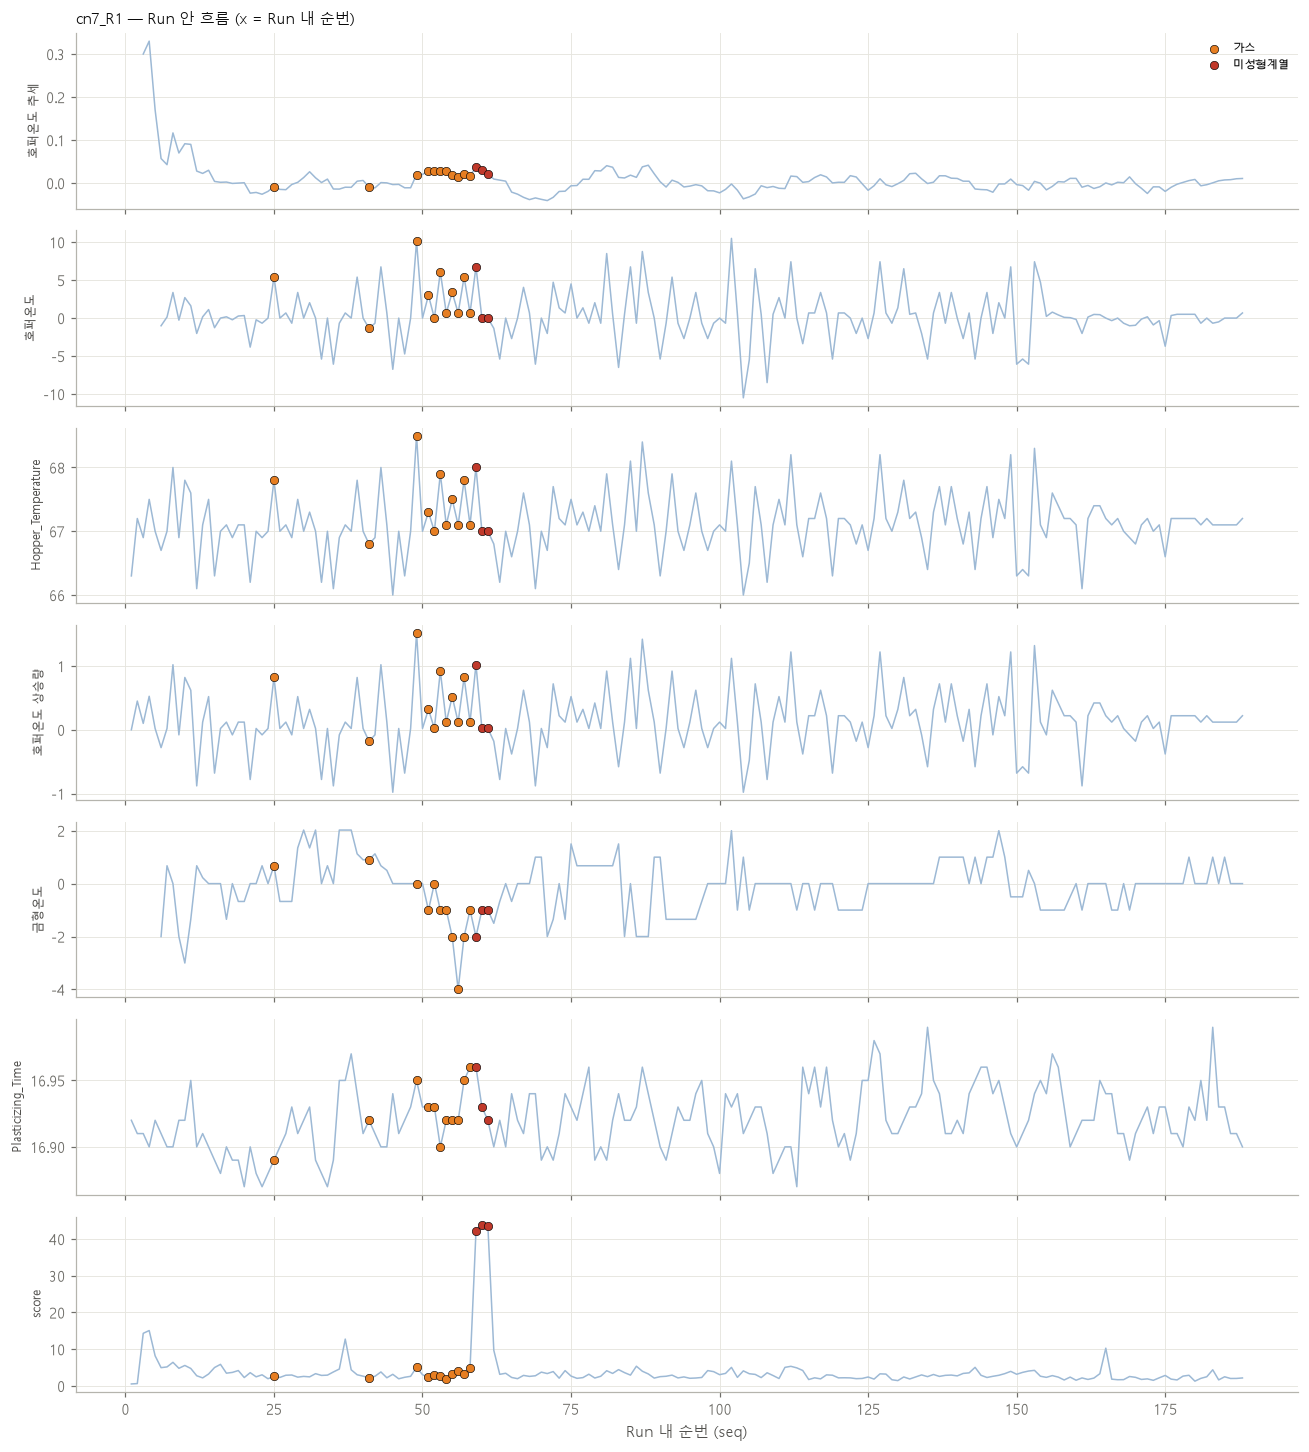

In [6]:
g2 = G[G['비교'].str.startswith('②') & (G['변수'] != 'score')]
top = g2.reindex(g2["Cliff's δ"].abs().sort_values(ascending=False).index)['변수'].head(6).tolist()
plot_timeline(d, top + ['score'], RUN, save=f'{OUT}/r1_timeline.png')

## 해석 가이드
- **① 대비 큰데 ② 대비 작음** → R1 안에서 시간이 흐르며 생긴 변화(예: 온도 상승)일 뿐, 가스 샷 자체의 특징은 아님
- **②에서도 |δ| 큼 + q < 0.1** → 가스 샷 자체가 주변 정상과 다른 변수 = 가스 탐지에 쓸 수 있는 후보
- **②에서 큰 변수가 없음** → R1 안에서도 가스는 공정값으로 구분 안 됨 (가스 AP가 낮은 이유)